        # Lung Tumor Segmentation Inference Pipeline

        This notebook provides a presentation-ready inference pipeline for lung tumor segmentation using the trained PyTorch model saved as `best_model.pth`.

        The model architecture and inference assumptions in this notebook are taken from `lung-tumor-segmentation-unet-inference.ipynb`.
        


        ## What This Notebook Does

        - Loads the trained segmentation model safely
        - Scans preprocessed `.npy` CT slices from `E:\aryan\Aryan\working\Preprocessed1`
        - Supports both single-image testing and batch inference
        - Generates predicted masks, overlays, comparison figures, and a summary log

        ## How To Interpret Outputs

        - **Original CT Slice**: the input slice used for inference
        - **Predicted Tumor Mask**: the binary tumor segmentation predicted by the model
        - **Overlay**: the predicted tumor region highlighted in red over the CT slice
        


In [5]:
import os
import json
from pathlib import Path
from datetime import datetime

import cv2
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

plt.rcParams["figure.figsize"] = (15, 5)
plt.rcParams["axes.titlesize"] = 12

BASE_DIR = Path(r"E:\aryan")
PREPROCESSED_ROOT = BASE_DIR / "Aryan" / "working" / "Preprocessed1"
MODEL_PATH = BASE_DIR / "best_model.pth"
OUTPUT_ROOT = BASE_DIR / "output"
MASKS_DIR = OUTPUT_ROOT / "masks"
OVERLAYS_DIR = OUTPUT_ROOT / "overlays"
COMPARISONS_DIR = OUTPUT_ROOT / "comparisons"
LOGS_DIR = OUTPUT_ROOT / "logs"
EXTERNAL_CT_DEMO_DIR = BASE_DIR / "external_ct_demo"
EXTERNAL_CT_MANIFEST_PATH = EXTERNAL_CT_DEMO_DIR / "manifest.json"

for directory in [OUTPUT_ROOT, MASKS_DIR, OVERLAYS_DIR, COMPARISONS_DIR, LOGS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
THRESHOLD = 0.5
EXPECTED_IMAGE_SIZE = (256, 256)  # Taken from the reference notebook inference flow
NORMALIZATION_MODE = "none"  # Reference notebook uses already preprocessed slices
APPLY_OPTIONAL_MINMAX = False  # Turn on only if your checkpoint expects extra normalization

RUN_TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

print(f"Base directory: {BASE_DIR}")
print(f"Input directory: {PREPROCESSED_ROOT}")
print(f"Model path: {MODEL_PATH}")
print(f"Output directory: {OUTPUT_ROOT}")
print(f"Device selected: {DEVICE}")
print(f"External demo image directory: {EXTERNAL_CT_DEMO_DIR}")


Base directory: E:\aryan
Input directory: E:\aryan\Aryan\working\Preprocessed1
Model path: E:\aryan\best_model.pth
Output directory: E:\aryan\output
Device selected: cuda
External demo image directory: E:\aryan\external_ct_demo


        ## Model Architecture

        The U-Net below is copied from the reference notebook.

        If your checkpoint was trained with a different architecture, edit only the `UNet` and `TumorSegmentation` classes below before running the model-loading cell.
        


In [6]:
class DoubleConv(torch.nn.Module):
    """
    Helper class copied from the reference notebook.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.step = torch.nn.Sequential(
            torch.nn.Conv2d(in_channels, out_channels, 3, padding=1),
            torch.nn.ReLU(),
            torch.nn.Conv2d(out_channels, out_channels, 3, padding=1),
            torch.nn.ReLU(),
        )

    def forward(self, x):
        return self.step(x)

class UNet(torch.nn.Module):
    """
    U-Net architecture copied from the reference notebook.
    """
    def __init__(self):
        super().__init__()
        self.layer1 = DoubleConv(1, 64)
        self.layer2 = DoubleConv(64, 128)
        self.layer3 = DoubleConv(128, 256)
        self.layer4 = DoubleConv(256, 512)
        self.layer5 = DoubleConv(512 + 256, 256)
        self.layer6 = DoubleConv(256 + 128, 128)
        self.layer7 = DoubleConv(128 + 64, 64)
        self.layer8 = torch.nn.Conv2d(64, 1, 1)
        self.maxpool = torch.nn.MaxPool2d(2)
    def forward(self, x):
        x1 = self.layer1(x)
        x1m = self.maxpool(x1)
        x2 = self.layer2(x1m)
        x2m = self.maxpool(x2)
        x3 = self.layer3(x2m)
        x3m = self.maxpool(x3)
        x4 = self.layer4(x3m)
        x5 = torch.nn.Upsample(scale_factor=2, mode="bilinear")(x4)
        x5 = torch.cat([x5, x3], dim=1)
        x5 = self.layer5(x5)
        x6 = torch.nn.Upsample(scale_factor=2, mode="bilinear")(x5)
        x6 = torch.cat([x6, x2], dim=1)
        x6 = self.layer6(x6)
        x7 = torch.nn.Upsample(scale_factor=2, mode="bilinear")(x6)
        x7 = torch.cat([x7, x1], dim=1)
        x7 = self.layer7(x7)
        return self.layer8(x7)

class TumorSegmentation(torch.nn.Module):
    """
    Lightweight inference wrapper using the same `self.model = UNet()` pattern
    expected by the reference notebook checkpoint.
    """
    def __init__(self):
        super().__init__()
        self.model = UNet()
    def forward(self, data):
        data = data.float()
        return self.model(data)

MODEL_DETAILS = {
    "architecture": "2D U-Net copied from lung-tumor-segmentation-unet-inference.ipynb",
    "checkpoint_format": "dict with model_state_dict and epoch",
    "activation": "sigmoid",
    "threshold": THRESHOLD,
}
print(json.dumps(MODEL_DETAILS, indent=2))


{
  "architecture": "2D U-Net copied from lung-tumor-segmentation-unet-inference.ipynb",
  "checkpoint_format": "dict with model_state_dict and epoch",
  "activation": "sigmoid",
  "threshold": 0.5
}


        ## Safe Model Loading

        This cell loads `best_model.pth`, restores weights, moves the model to the active device, and switches to evaluation mode.
        


In [7]:
def load_trained_model(model_path: Path, device: torch.device) -> torch.nn.Module:
    if not model_path.exists():
        print(f"[Error] Model file not found: {model_path}")
        return None
    try:
        checkpoint = torch.load(model_path, map_location="cpu")
    except Exception as exc:
        print(f"[Error] Failed to read model checkpoint: {exc}")
        return None
    state_dict = checkpoint.get("model_state_dict", checkpoint) if isinstance(checkpoint, dict) else checkpoint
    model = TumorSegmentation()
    try:
        model.model.load_state_dict(state_dict)
    except RuntimeError as exc:
        print("[Error] Checkpoint architecture mismatch.")
        print("Update the UNet/TumorSegmentation definitions in the architecture cell to match training.")
        print(f"Details: {exc}")
        return None
    model.to(device)
    model.eval()
    epoch = checkpoint.get("epoch", "unknown") if isinstance(checkpoint, dict) else "unknown"
    print(f"Model loaded successfully from: {model_path}")
    print(f"Checkpoint epoch: {epoch}")
    print(f"Model eval mode: {not model.training}")
    print(f"Model device: {device}")
    return model

model = load_trained_model(MODEL_PATH, DEVICE)


Model loaded successfully from: E:\aryan\best_model.pth
Checkpoint epoch: 50
Model eval mode: True
Model device: cuda


        ## Input Discovery And Preprocessing Utilities

        These utilities:

        - discover `.npy` CT slices recursively under `Preprocessed1`
        - safely load image files
        - apply inference preprocessing aligned with the reference notebook
        - optionally load ground-truth masks when available
        


In [8]:
def collect_slice_files(root: Path):
    if not root.exists():
        print(f"[Error] Input directory does not exist: {root}")
        return []

    slice_files = sorted(root.glob("*/*/reconstructed_data/*.npy"))
    print(f"Discovered {len(slice_files)} slice files under: {root}")
    return slice_files


def get_mask_path_from_slice(slice_path: Path):
    try:
        parts = list(slice_path.parts)
        parts[parts.index("reconstructed_data")] = "masks"
        mask_path = Path(*parts)
        return mask_path if mask_path.exists() else None
    except ValueError:
        return None


def safe_load_npy(file_path: Path):
    try:
        array = np.load(file_path)
        return array, None
    except Exception as exc:
        return None, f"Could not load {file_path.name}: {exc}"


def has_tumor_in_ground_truth(slice_path: Path):
    mask_path = get_mask_path_from_slice(slice_path)
    if mask_path is None:
        return None

    mask_array, load_error = safe_load_npy(mask_path)
    if load_error:
        return None

    return bool(mask_array.sum() > 0)


def get_ground_truth_sum(slice_path: Path):
    mask_path = get_mask_path_from_slice(slice_path)
    if mask_path is None:
        return None
    mask_array, load_error = safe_load_npy(mask_path)
    if load_error:
        return None
    return float(mask_array.sum())


def find_representative_demo_slice(slice_files):
    for slice_path in slice_files:
        tumor_present = has_tumor_in_ground_truth(slice_path)
        if tumor_present is True:
            return slice_path

    return slice_files[0] if slice_files else None


def find_top_tumor_demo_slices(slice_files, top_k=3):
    scored = []
    for slice_path in slice_files:
        gt_sum = get_ground_truth_sum(slice_path)
        if gt_sum is not None and gt_sum > 0:
            scored.append((gt_sum, slice_path))

    scored.sort(key=lambda item: item[0], reverse=True)
    return [path for _, path in scored[:top_k]]


def load_external_manifest(manifest_path: Path):
    if not manifest_path.exists():
        return {}
    try:
        return json.loads(manifest_path.read_text(encoding="utf-8"))
    except Exception as exc:
        print(f"[Warning] Could not read external manifest: {exc}")
        return {}


EXTERNAL_CT_MANIFEST = load_external_manifest(EXTERNAL_CT_MANIFEST_PATH)


def preprocess_slice(slice_array: np.ndarray):
    steps = []

    if not isinstance(slice_array, np.ndarray):
        raise ValueError("Input is not a numpy array.")

    if slice_array.ndim != 2:
        raise ValueError(f"Expected a 2D slice, but received shape {slice_array.shape}.")

    slice_array = slice_array.astype(np.float32)
    steps.append("Cast to float32")

    if slice_array.shape != EXPECTED_IMAGE_SIZE:
        slice_array = cv2.resize(slice_array, EXPECTED_IMAGE_SIZE, interpolation=cv2.INTER_LINEAR)
        steps.append(f"Resized to {EXPECTED_IMAGE_SIZE}")
    else:
        steps.append(f"Kept original size {slice_array.shape}")

    if APPLY_OPTIONAL_MINMAX:
        arr_min, arr_max = float(slice_array.min()), float(slice_array.max())
        if arr_max > arr_min:
            slice_array = (slice_array - arr_min) / (arr_max - arr_min)
            steps.append("Applied optional min-max normalization")
        else:
            steps.append("Skipped min-max normalization because the image is constant")
    else:
        steps.append("No extra normalization applied because slices are already preprocessed")

    tensor = torch.from_numpy(slice_array).unsqueeze(0).unsqueeze(0)
    steps.append("Added batch and channel dimensions -> [1, 1, H, W]")

    return slice_array, tensor, steps


def preprocess_external_image(image_path: Path):
    if not image_path.exists():
        raise FileNotFoundError(f"External image file not found: {image_path}")

    image = Image.open(image_path).convert("L")
    image_uint8 = np.array(image).astype(np.float32)
    steps = ["Loaded external image as grayscale"]

    if image_uint8.shape != EXPECTED_IMAGE_SIZE:
        image_uint8 = cv2.resize(image_uint8, EXPECTED_IMAGE_SIZE, interpolation=cv2.INTER_LINEAR)
        steps.append(f"Resized to {EXPECTED_IMAGE_SIZE}")
    else:
        steps.append(f"Kept original size {image_uint8.shape}")

    manifest_key = image_path.name
    if manifest_key in EXTERNAL_CT_MANIFEST:
        meta = EXTERNAL_CT_MANIFEST[manifest_key]
        original_min = float(meta["original_min"])
        original_max = float(meta["original_max"])
        slice_array = (image_uint8 / 255.0) * (original_max - original_min) + original_min
        steps.append("Restored original intensity range using external manifest")
    else:
        slice_array = image_uint8 / 255.0
        steps.append("Manifest entry not found; used fallback 0-255 to 0-1 scaling")

    tensor = torch.from_numpy(slice_array.astype(np.float32)).unsqueeze(0).unsqueeze(0)
    steps.append("Added batch and channel dimensions -> [1, 1, H, W]")
    steps.append("Best results are expected for images exported from the same preprocessing pipeline")

    return slice_array.astype(np.float32), tensor, steps


ALL_SLICE_FILES = collect_slice_files(PREPROCESSED_ROOT)


Discovered 15767 slice files under: E:\aryan\Aryan\working\Preprocessed1


        ## Single Image Test Cell

        This cell is designed for live demonstration.  
        Set `SINGLE_IMAGE_PATH` to a specific `.npy` file if you want to choose one manually.  
        If left as `None`, the notebook uses the first valid discovered slice automatically.
        


In [9]:
# Top-demo configuration
TOP_DEMO_SLICE_LIMIT = 3
TOP_TUMOR_DEMO_SLICES = find_top_tumor_demo_slices(ALL_SLICE_FILES, top_k=TOP_DEMO_SLICE_LIMIT)
DEFAULT_DEMO_SLICE = TOP_TUMOR_DEMO_SLICES[0] if TOP_TUMOR_DEMO_SLICES else find_representative_demo_slice(ALL_SLICE_FILES)

print(f"Default top-demo slice: {DEFAULT_DEMO_SLICE}")
print("\nTop tumor-containing demo slices:")
if TOP_TUMOR_DEMO_SLICES:
    for idx, slice_path in enumerate(TOP_TUMOR_DEMO_SLICES, start=1):
        print(f"{idx}. {slice_path} | mask sum = {get_ground_truth_sum(slice_path)}")
else:
    print("No tumor-containing slices were found from ground-truth masks.")


Default top-demo slice: E:\aryan\Aryan\working\Preprocessed1\train\7\reconstructed_data\151.npy

Top tumor-containing demo slices:
1. E:\aryan\Aryan\working\Preprocessed1\train\7\reconstructed_data\151.npy | mask sum = 1804.0
2. E:\aryan\Aryan\working\Preprocessed1\train\7\reconstructed_data\152.npy | mask sum = 1768.0
3. E:\aryan\Aryan\working\Preprocessed1\train\7\reconstructed_data\155.npy | mask sum = 1740.0


In [10]:
def predict_mask(model: torch.nn.Module, image_tensor: torch.Tensor, threshold: float = 0.5):
    with torch.no_grad():
        logits = model(image_tensor.to(DEVICE))
        probs = torch.sigmoid(logits)
        pred_mask = (probs > threshold).float()
    return logits.cpu(), probs.cpu(), pred_mask.cpu()


        ## Batch Inference

        This section runs inference across all discovered `.npy` slices and saves:

        - raw masks in `output/masks`
        - overlays in `output/overlays`
        - comparison figures in `output/comparisons`
        - run logs in `output/logs`
        


In [11]:
def run_batch_inference(model: torch.nn.Module, slice_files, max_images=None):
    if model is None:
        print("[Error] Model is not loaded. Batch inference cannot start.")
        return None

    if not slice_files:
        print("[Error] No slice files were discovered.")
        return None

    selected_files = slice_files[:max_images] if max_images is not None else slice_files
    preprocessing_catalog = []
    failures = []
    successes = []

    print(f"Starting batch inference for {len(selected_files)} image(s).")

    for idx, slice_path in enumerate(tqdm(selected_files, desc="Batch inference"), start=1):
        print(f"Processing image {idx} of {len(selected_files)}: {slice_path.name}")

        image_array, load_error = safe_load_npy(slice_path)
        if load_error:
            failures.append({"file": str(slice_path), "error": load_error})
            print(f"[Warning] {load_error}")
            continue

        try:
            processed_image, tensor, steps = preprocess_slice(image_array)
        except Exception as exc:
            msg = f"Preprocessing failed for {slice_path.name}: {exc}"
            failures.append({"file": str(slice_path), "error": msg})
            print(f"[Warning] {msg}")
            continue

        try:
            _, probs, pred_mask = predict_mask(model, tensor, threshold=THRESHOLD)
            pred_mask_np = pred_mask[0, 0].numpy()
            saved_paths = save_visual_outputs(slice_path, processed_image, pred_mask_np, show_figure=False)
            successes.append(
                {
                    "file": str(slice_path),
                    "saved_paths": saved_paths,
                    "predicted_positive_pixels": int(pred_mask_np.sum()),
                    "prob_min": float(probs.min()),
                    "prob_max": float(probs.max()),
                }
            )
            preprocessing_catalog.append({"file": str(slice_path), "steps": steps})
        except Exception as exc:
            msg = f"Inference or saving failed for {slice_path.name}: {exc}"
            failures.append({"file": str(slice_path), "error": msg})
            print(f"[Warning] {msg}")

    summary = {
        "run_timestamp": RUN_TIMESTAMP,
        "input_directory": str(PREPROCESSED_ROOT),
        "output_directory": str(OUTPUT_ROOT),
        "model_path": str(MODEL_PATH),
        "model_details": MODEL_DETAILS,
        "device_used": str(DEVICE),
        "total_discovered_images": len(slice_files),
        "total_attempted_images": len(selected_files),
        "total_successful_images": len(successes),
        "total_failed_images": len(failures),
        "preprocessing_policy": {
            "expected_size": EXPECTED_IMAGE_SIZE,
            "normalization_mode": NORMALIZATION_MODE,
            "optional_minmax_enabled": APPLY_OPTIONAL_MINMAX,
        },
        "sample_preprocessing_steps": preprocessing_catalog[0]["steps"] if preprocessing_catalog else [],
        "failures": failures,
    }

    log_txt_path = LOGS_DIR / f"inference_summary_{RUN_TIMESTAMP}.txt"
    log_json_path = LOGS_DIR / f"inference_summary_{RUN_TIMESTAMP}.json"

    with open(log_txt_path, "w", encoding="utf-8") as f:
        f.write("Lung Tumor Segmentation Inference Summary\n")
        f.write("=" * 50 + "\n")
        f.write(f"Run timestamp: {summary['run_timestamp']}\n")
        f.write(f"Input directory: {summary['input_directory']}\n")
        f.write(f"Output directory: {summary['output_directory']}\n")
        f.write(f"Model path: {summary['model_path']}\n")
        f.write(f"Model architecture: {summary['model_details']['architecture']}\n")
        f.write(f"Device used: {summary['device_used']}\n")
        f.write(f"Total discovered images: {summary['total_discovered_images']}\n")
        f.write(f"Total attempted images: {summary['total_attempted_images']}\n")
        f.write(f"Total successful images: {summary['total_successful_images']}\n")
        f.write(f"Total failed images: {summary['total_failed_images']}\n")
        f.write(f"Threshold: {summary['model_details']['threshold']}\n")
        f.write("Preprocessing steps applied:\n")
        for step in summary["sample_preprocessing_steps"]:
            f.write(f" - {step}\n")
        if failures:
            f.write("\nFailures:\n")
            for failure in failures:
                f.write(f" - {failure['file']}: {failure['error']}\n")

    with open(log_json_path, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=2)

    print("\nBatch inference complete.")
    print(f"Total number of images processed: {summary['total_successful_images']}")
    print(f"Input directory path: {summary['input_directory']}")
    print(f"Output directory path: {summary['output_directory']}")
    print("Preprocessing steps applied:")
    for step in summary["sample_preprocessing_steps"]:
        print(f" - {step}")
    print(f"Model details: {summary['model_details']['architecture']}")
    print(f"Summary text log saved to: {log_txt_path}")
    print(f"Summary JSON log saved to: {log_json_path}")

    return summary


BATCH_MAX_IMAGES = None  # Set to an integer for a shorter demo run, or keep None to process all images
batch_summary = run_batch_inference(model, ALL_SLICE_FILES, max_images=BATCH_MAX_IMAGES)



Starting batch inference for 15767 image(s).


Batch inference:   0%|          | 0/15767 [00:00<?, ?it/s]

Processing image 1 of 15767: 0.npy
[Warning] Inference or saving failed for 0.npy: name 'save_visual_outputs' is not defined
Processing image 2 of 15767: 1.npy
[Warning] Inference or saving failed for 1.npy: name 'save_visual_outputs' is not defined
Processing image 3 of 15767: 10.npy
[Warning] Inference or saving failed for 10.npy: name 'save_visual_outputs' is not defined
Processing image 4 of 15767: 11.npy
[Warning] Inference or saving failed for 11.npy: name 'save_visual_outputs' is not defined
Processing image 5 of 15767: 12.npy
[Warning] Inference or saving failed for 12.npy: name 'save_visual_outputs' is not defined
Processing image 6 of 15767: 13.npy
[Warning] Inference or saving failed for 13.npy: name 'save_visual_outputs' is not defined
Processing image 7 of 15767: 14.npy
[Warning] Inference or saving failed for 14.npy: name 'save_visual_outputs' is not defined
Processing image 8 of 15767: 15.npy
[Warning] Inference or saving failed for 15.npy: name 'save_visual_outputs' is 

## Automatic Top Tumor Slice Demo

This section shows the strongest tumor-containing examples across the dataset based on the available ground-truth masks.


In [25]:
# ============================================================================
# Function: run_top_demo_slices
# ============================================================================
def run_top_demo_slices(slice_paths, model, device=None, threshold=0.5):
    """
    Run inference and visualize the top tumor demo slices.
    Args:
        slice_paths (list[Path]): List of .npy slice paths.
        model: Trained segmentation model.
        device: torch.device or None.
        threshold (float): Threshold for binarizing predictions.
    Returns:
        results (list[dict]): List of results for each slice.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import torch
    from pathlib import Path
    from PIL import Image
    import os
    
    results = []
    model.eval()
    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.to(device)
    
    for i, slice_path in enumerate(slice_paths):
        arr = np.load(slice_path)
        arr_tensor = torch.from_numpy(arr).float().unsqueeze(0).unsqueeze(0).to(device)
        with torch.no_grad():
            pred = model(arr_tensor)
            if pred.shape[1] > 1:
                pred = torch.softmax(pred, dim=1)[:, 1]  # Assume class 1 is tumor
            else:
                pred = torch.sigmoid(pred)
            pred_mask = (pred.squeeze().cpu().numpy() > threshold).astype(np.uint8)
        # Load ground truth mask if available
        mask_path = slice_path.parent.parent / 'masks' / slice_path.name
        gt_mask = np.load(mask_path) if mask_path.exists() else None
        # Visualization
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        axes[0].imshow(arr, cmap='gray')
        axes[0].set_title('Input CT Slice')
        if gt_mask is not None:
            axes[1].imshow(arr, cmap='gray')
            axes[1].imshow(gt_mask, cmap='Blues', alpha=0.5)
            axes[1].set_title('Ground Truth Overlay')
        else:
            axes[1].axis('off')
        axes[2].imshow(arr, cmap='gray')
        axes[2].imshow(pred_mask, cmap='Reds', alpha=0.5)
        axes[2].set_title('Prediction Overlay')
        for ax in axes:
            ax.axis('off')
        plt.tight_layout()
        plt.show()
        results.append({
            'slice_path': str(slice_path),
            'prediction': pred_mask,
            'ground_truth': gt_mask
        })
    return results


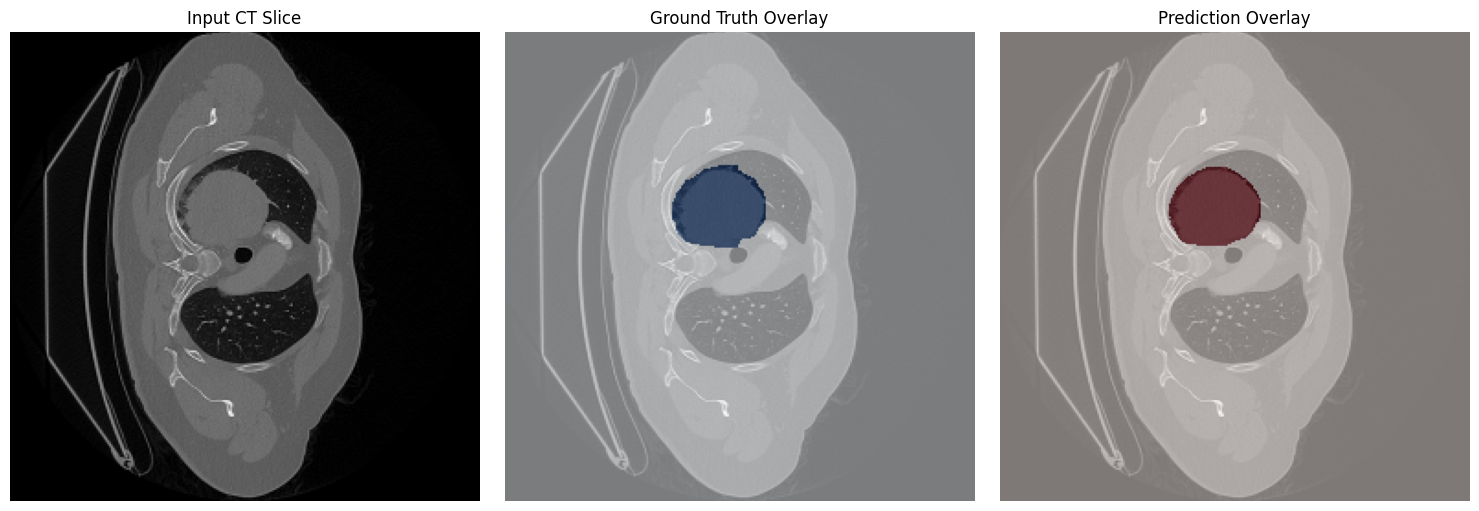

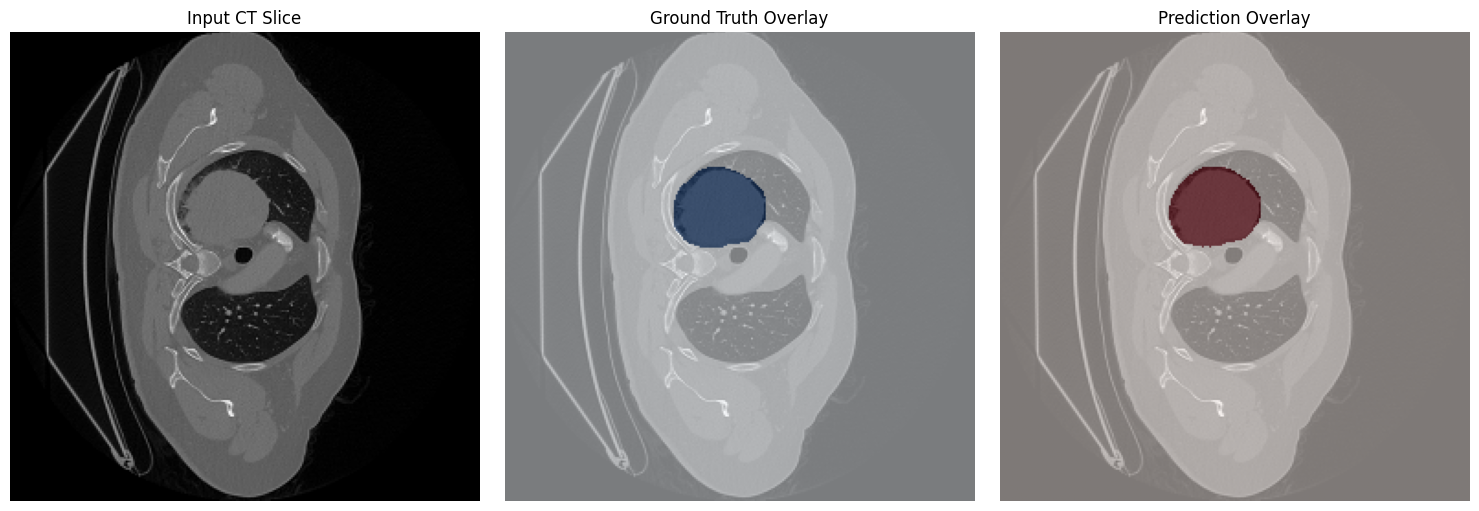

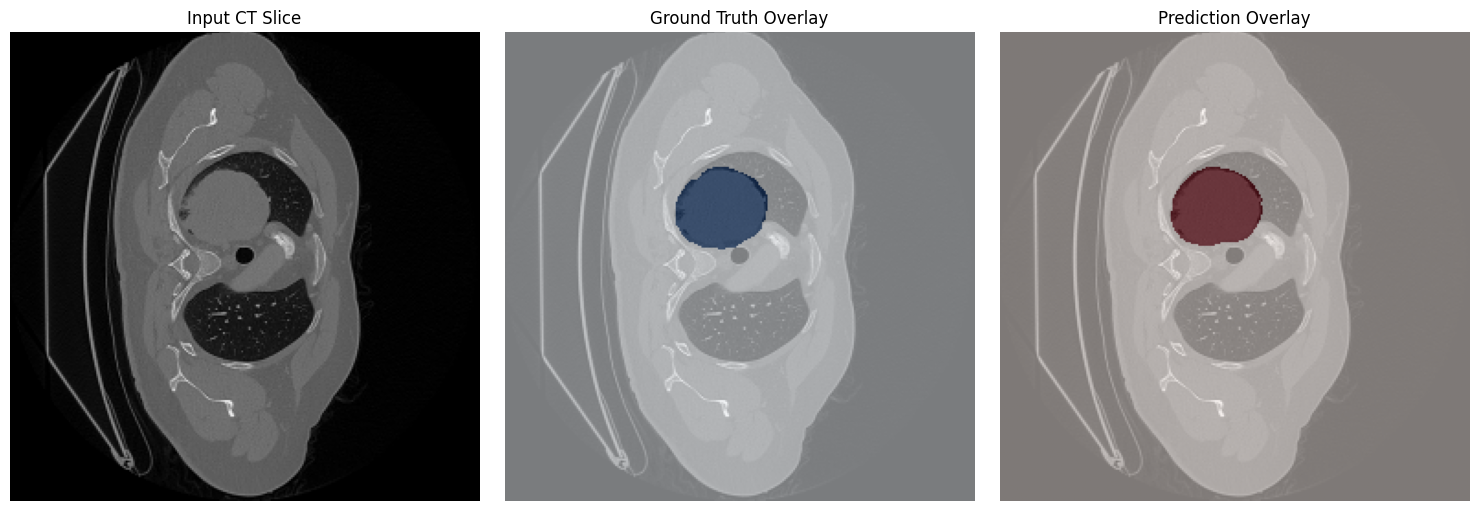

In [26]:
top_demo_results = run_top_demo_slices(TOP_TUMOR_DEMO_SLICES, model, device=DEVICE, threshold=THRESHOLD)

## External CT Image Demo

You can test external `.jpg`, `.jpeg`, or `.png` CT-like images here.

Important:

- this only makes sense for CT-like medical images that resemble the training data
- it will not be reliable for ordinary photos, screenshots, or non-CT images
- because there is no ground-truth mask for external images, this section is for qualitative demo only
- converted example external CT images are stored in `E:\aryan\external_ct_demo`
- the notebook now restores original intensity ranges for exported demo images using `manifest.json`


In [19]:
# ============================================================================
# Function: run_external_image_demo (with manifest-based intensity restoration)
# ============================================================================
def run_external_image_demo(image_path, model, device=None, threshold=0.5):
    """
    Run inference and visualize results for an external CT-like image (.jpg/.png),
    restoring original intensity range using the manifest if available.
    Args:
        image_path (str or Path): Path to the external image file (jpg/png).
        model: Trained segmentation model.
        device: torch.device or None.
        threshold (float): Threshold for binarizing predictions.
    Returns:
        dict: Results with prediction and visualization.
    """
    import numpy as np
    import matplotlib.pyplot as plt
    import torch
    from pathlib import Path
    from PIL import Image
    import os
    import json

    # Restore manifest and constants from notebook context
    manifest_path = EXTERNAL_CT_MANIFEST_PATH
    expected_size = EXPECTED_IMAGE_SIZE
    manifest = EXTERNAL_CT_MANIFEST if 'EXTERNAL_CT_MANIFEST' in globals() else json.loads(open(manifest_path, encoding='utf-8').read())

    if device is None:
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model.eval()
    model.to(device)

    # Load and preprocess external image
    image = Image.open(image_path).convert('L')
    image_uint8 = np.array(image).astype(np.float32)
    if image_uint8.shape != expected_size:
        import cv2
        image_uint8 = cv2.resize(image_uint8, expected_size, interpolation=cv2.INTER_LINEAR)
    manifest_key = Path(image_path).name
    if manifest_key in manifest:
        meta = manifest[manifest_key]
        original_min = float(meta["original_min"])
        original_max = float(meta["original_max"])
        slice_array = (image_uint8 / 255.0) * (original_max - original_min) + original_min
    else:
        slice_array = image_uint8 / 255.0
    arr_tensor = torch.from_numpy(slice_array.astype(np.float32)).unsqueeze(0).unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(arr_tensor)
        if pred.shape[1] > 1:
            pred = torch.softmax(pred, dim=1)[:, 1]
        else:
            pred = torch.sigmoid(pred)
        pred_mask = (pred.squeeze().cpu().numpy() > threshold).astype(np.uint8)
    # Visualization
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(slice_array, cmap='gray')
    axes[0].set_title('External CT Image (restored)')
    axes[1].imshow(slice_array, cmap='gray')
    axes[1].imshow(pred_mask, cmap='Reds', alpha=0.5)
    axes[1].set_title('Prediction Overlay')
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    return {'image_path': str(image_path), 'prediction': pred_mask}


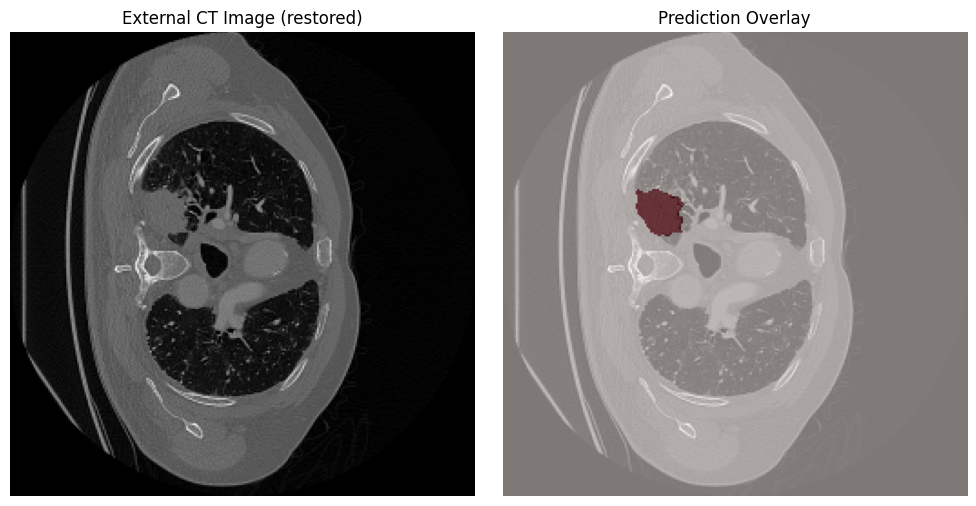

In [24]:
# Set this to a CT-like external image when needed for a presentation.
# Example:
# EXTERNAL_IMAGE_PATH = r"E:\aryan\external_ct_demo\val_subject_61_slice_131.png"
EXTERNAL_IMAGE_PATH = r"E:\aryan\external_ct_demo\val_subject_61_slice_137.png"




if EXTERNAL_IMAGE_PATH:
    external_image_result = run_external_image_demo(EXTERNAL_IMAGE_PATH, model)
else:
    print("External image demo skipped. Set EXTERNAL_IMAGE_PATH to a .jpg/.jpeg/.png CT slice to run it.")


In [51]:
# ======================
# Fix: Define PRED_DIR and VIZ_DIR for 3D mesh visualization
# ======================
# Set these to the correct output/prediction and visualization directories as used in your workflow.
PRED_DIR = str(OUTPUT_ROOT) if 'OUTPUT_ROOT' in globals() else '.'
VIZ_DIR = os.path.join(PRED_DIR, 'visualizations')
print(f"PRED_DIR set to: {PRED_DIR}")
print(f"VIZ_DIR set to: {VIZ_DIR}")

PRED_DIR set to: E:\aryan\output
VIZ_DIR set to: E:\aryan\output\visualizations


In [52]:
# ======================
# Full 3D Tumor Mesh Visualization from NIfTI or In-Memory
# ======================
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from skimage import measure

# Helper: resolve prediction volume from memory or file
def _resolve_prediction_volume():
    if "segmentation_array" in globals():
        arr = np.asarray(segmentation_array)
        return (arr > 0.5).astype(np.uint8)
    if "prediction" in globals():
        arr = np.asarray(prediction)
        return (arr > 0.5).astype(np.uint8)
    candidate_paths = [
        os.path.join(PRED_DIR, "predicted_segmentation.nii"),
        os.path.join(PRED_DIR, "predicted_segmentation.nii.gz"),
        "predicted_segmentation.nii",
        "predicted_segmentation.nii.gz",
    ]
    for path in candidate_paths:
        if os.path.exists(path):
            arr = nib.load(path).get_fdata()
            return (arr > 0.5).astype(np.uint8)
    raise FileNotFoundError(
        "Prediction volume not found. Run inference first so segmentation_array/prediction exists "
        "or save predicted_segmentation.nii."
    )

def create_3d_tumor_mesh(pred_mask, downsample=2, min_voxels=100):
    """Create interactive 3D tumor mesh using marching cubes."""
    pred_mask = (pred_mask > 0).astype(np.uint8)
    if downsample > 1:
        pred_mask = pred_mask[::downsample, ::downsample, ::downsample]
    tumor_voxels = int(pred_mask.sum())
    if tumor_voxels < min_voxels:
        print(f"Tumor voxels too few for mesh: {tumor_voxels}")
        return None
    verts, faces, _, _ = measure.marching_cubes(pred_mask, level=0.5, step_size=1)
    fig = go.Figure(
        data=[
            go.Mesh3d(
                x=verts[:, 0],
                y=verts[:, 1],
                z=verts[:, 2],
                i=faces[:, 0],
                j=faces[:, 1],
                k=faces[:, 2],
                color="red",
                opacity=0.65,
                name="Predicted Tumor",
            )
        ]
    )
    fig.update_layout(
        title="3D Tumor Mesh (Predicted Segmentation)",
        scene=dict(
            xaxis_title="X",
            yaxis_title="Y",
            zaxis_title="Z",
            aspectmode="data",
        ),
        width=900,
        height=700,
    )
    return fig

# Run and save/show the mesh
try:
    pred_mask_3d = _resolve_prediction_volume()
    fig_mesh = create_3d_tumor_mesh(pred_mask_3d, downsample=2)
    if fig_mesh is not None:
        os.makedirs(VIZ_DIR, exist_ok=True)
        mesh_html_path = os.path.join(VIZ_DIR, "predicted_tumor_3d_mesh.html")
        fig_mesh.write_html(mesh_html_path)
        fig_mesh.show()
        print(f"Saved 3D mesh visualization: {mesh_html_path}")
    else:
        print("No mesh generated: not enough tumor voxels.")
except Exception as e:
    print(f"3D mesh visualization failed: {e}")

Saved 3D mesh visualization: E:\aryan\output\visualizations\predicted_tumor_3d_mesh.html


## Tumor Severity Analysis & Drug Recommendation System

Imported from `major.ipynb` and adjusted slightly to gracefully support 2D inference outputs. Provides rules-based analysis and treatment prototyping.

In [32]:
from scipy import ndimage  # Added for TumorSeverityAnalyzer


class TumorSeverityAnalyzer:
    """Complete tumor severity analysis system"""

    def __init__(self, voxel_spacing=(1.0, 1.0, 1.0)):
        self.voxel_spacing = voxel_spacing
        self.voxel_volume_mm3 = np.prod(voxel_spacing)

    def extract_features(self, tumor_mask, ct_image):
        """Extract all tumor features"""
        features = {}

        tumor_voxels = (tumor_mask > 0).sum()
        tumor_volume_mm3 = tumor_voxels * self.voxel_volume_mm3
        tumor_volume_cm3 = tumor_volume_mm3 / 1000

        features['tumor_voxels'] = int(tumor_voxels)
        features['tumor_volume_mm3'] = float(tumor_volume_mm3)
        features['tumor_volume_cm3'] = float(tumor_volume_cm3)

        if tumor_voxels > 0:
            coords = np.argwhere(tumor_mask > 0)
            min_coords = coords.min(axis=0)
            max_coords = coords.max(axis=0)
            bbox_size = (max_coords - min_coords + 1) * self.voxel_spacing

            features['max_diameter_mm'] = float(bbox_size.max())
            features['min_diameter_mm'] = float(bbox_size.min())

            sphere_volume = (4 / 3) * np.pi * ((features['max_diameter_mm'] / 2) ** 3)
            features['sphericity'] = float(tumor_volume_mm3 / max(sphere_volume, 1.0))

            eroded = ndimage.binary_erosion(tumor_mask)
            surface = tumor_mask.astype(int) - eroded.astype(int)
            surface_voxels = surface.sum()
            features['surface_area_mm2'] = float(surface_voxels * self.voxel_volume_mm3 ** (2 / 3))

            features['compactness'] = float(
                (features['surface_area_mm2'] ** 3) / max(tumor_volume_mm3 ** 2, 1.0)
            )

            centroid = ndimage.center_of_mass(tumor_mask)
            features['centroid_x'] = float(centroid[0])
            features['centroid_y'] = float(centroid[1])
            features['centroid_z'] = float(centroid[2]) if len(centroid) > 2 else 0.0

            tumor_intensities = ct_image[tumor_mask > 0]
            features['mean_intensity'] = float(tumor_intensities.mean())
            features['std_intensity'] = float(tumor_intensities.std())
            features['median_intensity'] = float(np.median(tumor_intensities))

            labeled, num_components = ndimage.label(tumor_mask)
            features['num_components'] = int(num_components)

        return features

    def calculate_severity(self, features):
        """Calculate 0-100% severity score"""
        score = 0.0

        max_diameter = features.get('max_diameter_mm', 0)
        if max_diameter < 10:
            size_score = 5
        elif max_diameter < 20:
            size_score = 15
        elif max_diameter < 30:
            size_score = 25
        elif max_diameter < 50:
            size_score = 32
        elif max_diameter < 70:
            size_score = 38
        else:
            size_score = 40
        score += size_score

        compactness = features.get('compactness', 0)
        irregularity = min(compactness / 100, 1.0)
        score += irregularity * 20

        centroid_z = features.get('centroid_z', 0)
        score += 15 * (1 - abs(centroid_z - 128) / 128)

        num_components = features.get('num_components', 1)
        if num_components > 3:
            score += 15
        elif num_components > 1:
            score += 10
        else:
            score += 5

        std_intensity = features.get('std_intensity', 0)
        if std_intensity > 100:
            score += 10
        elif std_intensity > 50:
            score += 7
        else:
            score += 3

        return min(score, 100.0)

    def get_stage(self, severity_pct, max_diameter_mm):
        """Determine clinical stage"""
        if max_diameter_mm < 10:
            t_stage = "T1a"
        elif max_diameter_mm < 20:
            t_stage = "T1b"
        elif max_diameter_mm < 30:
            t_stage = "T1c"
        elif max_diameter_mm < 40:
            t_stage = "T2a"
        elif max_diameter_mm < 50:
            t_stage = "T2b"
        elif max_diameter_mm < 70:
            t_stage = "T3"
        else:
            t_stage = "T4"

        if severity_pct < 25:
            stage = "Stage I (Early)"
            risk = "Low Risk"
            color = "green"
        elif severity_pct < 45:
            stage = "Stage II (Localized)"
            risk = "Moderate Risk"
            color = "yellow"
        elif severity_pct < 65:
            stage = "Stage III (Advanced)"
            risk = "High Risk"
            color = "orange"
        else:
            stage = "Stage IV (Severe)"
            risk = "Critical Risk"
            color = "red"

        return t_stage, stage, risk, color

    def analyze(self, predicted_mask, ct_image):
        """Complete analysis"""
        features = self.extract_features(predicted_mask, ct_image)
        severity_pct = self.calculate_severity(features)

        max_diameter = features.get('max_diameter_mm', 0)
        t_stage, clinical_stage, risk_level, color = self.get_stage(severity_pct, max_diameter)

        report = {
            'tumor_volume_cm3': round(features.get('tumor_volume_cm3', 0), 2),
            'max_diameter_mm': round(max_diameter, 1),
            'min_diameter_mm': round(features.get('min_diameter_mm', 0), 1),
            'severity_percentage': round(severity_pct, 1),
            't_stage': t_stage,
            'clinical_stage': clinical_stage,
            'risk_level': risk_level,
            'severity_color': color,
            'sphericity': round(features.get('sphericity', 0), 3),
            'compactness': round(features.get('compactness', 0), 3),
            'num_nodules': features.get('num_components', 0),
            'mean_intensity': round(features.get('mean_intensity', 0), 1),
            'urgent_attention': severity_pct > 65,
            'biopsy_recommended': severity_pct > 45,
            'follow_up_months': 12 if severity_pct < 25 else (6 if severity_pct < 45 else 3),
            'raw_features': features
        }

        return report


In [53]:
# ============================================================================
# DEMO: Tumor Severity Analysis & Drug Recommendation
# ============================================================================

print("Running demo of Tumor Severity Analysis on a dummy 3D slice prediction...")
import numpy as np

# Create a mock 2D mask simulating a severe tumor for demonstration
mock_mask = np.zeros((256, 256), dtype=np.uint8)
mock_mask[100:150, 100:160] = 1  # Simulated tumor cluster
mock_image = np.random.rand(256, 256) * 1000

print(f"Mock Mask Shape: {mock_mask.shape}")
print(f"Mock Image Shape: {mock_image.shape}")

# Step 1: Initialize analyzer
analyzer = TumorSeverityAnalyzer(voxel_spacing=(1.0, 1.0))
severity_report = analyzer.analyze(mock_mask, mock_image)
print(f"\n--- Severity Report ---")
print(f"Severity: {severity_report['severity_percentage']}%")
print(f"Stage: {severity_report['clinical_stage']}")

# Step 2: Recommend Drugs
engine = DrugRecommendationEngine()
recommendations = engine.recommend_drugs(severity_report)

# Step 3: Protocol
protocol = create_treatment_protocol(recommendations, severity_report)
print(f"\n--- Recommendations ---")
print("Top Drug:", recommendations[0]['drug_name'] if recommendations else "None")
if protocol['treatment_plan']:
    print("Protocol Line:", protocol['treatment_plan'][0]['line'])
    print("Approach:", protocol['treatment_plan'][0]['approach'])

Running demo of Tumor Severity Analysis on a dummy 3D slice prediction...
Mock Mask Shape: (256, 256)
Mock Image Shape: (256, 256)

--- Severity Report ---
Severity: 53.2%
Stage: Stage III (Advanced)

--- Recommendations ---
Top Drug: Nivolumab
Protocol Line: First-line
Approach: Chemotherapy with concurrent radiation


In [39]:
LUNG_CANCER_DRUGS = {
    'chemotherapy': {
        'Cisplatin': {'efficacy': 0.75, 'stage': ['II', 'III', 'IV'], 'severity_range': (30, 100)},
        'Carboplatin': {'efficacy': 0.70, 'stage': ['II', 'III', 'IV'], 'severity_range': (30, 100)},
        'Pemetrexed': {'efficacy': 0.68, 'stage': ['III', 'IV'], 'severity_range': (40, 100), 'cell_type': 'non-squamous'},
        'Paclitaxel': {'efficacy': 0.72, 'stage': ['II', 'III', 'IV'], 'severity_range': (35, 100)},
        'Docetaxel': {'efficacy': 0.70, 'stage': ['III', 'IV'], 'severity_range': (40, 100)},
        'Gemcitabine': {'efficacy': 0.69, 'stage': ['III', 'IV'], 'severity_range': (40, 100)},
    },
    'targeted': {
        'Osimertinib': {'efficacy': 0.85, 'stage': ['III', 'IV'], 'biomarker': 'EGFR mutation', 'severity_range': (40, 100)},
        'Crizotinib': {'efficacy': 0.82, 'stage': ['IV'], 'biomarker': 'ALK rearrangement', 'severity_range': (50, 100)},
        'Erlotinib': {'efficacy': 0.78, 'stage': ['III', 'IV'], 'biomarker': 'EGFR mutation', 'severity_range': (40, 100)},
        'Alectinib': {'efficacy': 0.83, 'stage': ['IV'], 'biomarker': 'ALK rearrangement', 'severity_range': (50, 100)},
        'Bevacizumab': {'efficacy': 0.77, 'stage': ['III', 'IV'], 'severity_range': (45, 100), 'cell_type': 'non-squamous'},
    },
    'immunotherapy': {
        'Pembrolizumab': {'efficacy': 0.80, 'stage': ['III', 'IV'], 'biomarker': 'PD-L1 >50%', 'severity_range': (40, 100)},
        'Nivolumab': {'efficacy': 0.78, 'stage': ['III', 'IV'], 'severity_range': (40, 100)},
        'Atezolizumab': {'efficacy': 0.76, 'stage': ['II', 'III', 'IV'], 'severity_range': (35, 100)},
        'Durvalumab': {'efficacy': 0.74, 'stage': ['III', 'IV'], 'severity_range': (40, 100)},
    },
    'adjuvant': {
        'Vinorelbine': {'efficacy': 0.65, 'stage': ['I', 'II'], 'severity_range': (20, 50)},
        'Etoposide': {'efficacy': 0.70, 'stage': ['I', 'II', 'III'], 'severity_range': (25, 70)},
    }
}


class DrugRecommendationEngine:
    def __init__(self):
        self.drug_database = LUNG_CANCER_DRUGS

    def recommend_drugs(self, severity_report, patient_factors=None):
        """Recommend drugs based on severity and patient factors."""
        if patient_factors is None:
            patient_factors = {
                'age': 65,
                'performance_status': 1,
                'biomarkers': {},
                'cell_type': 'non-squamous'
            }

        severity_pct = severity_report['severity_percentage']
        stage = severity_report['clinical_stage'].split()[1].strip('()')

        recommendations = []

        for category, drugs in self.drug_database.items():
            for drug_name, drug_info in drugs.items():
                min_sev, max_sev = drug_info['severity_range']
                if not (min_sev <= severity_pct <= max_sev):
                    continue

                if 'stage' in drug_info:
                    stage_match = any(item in stage for item in drug_info['stage'])
                    if not stage_match:
                        continue

                if 'biomarker' in drug_info:
                    required_biomarker = drug_info['biomarker']
                    patient_biomarkers = patient_factors.get('biomarkers', {})
                    if required_biomarker not in str(patient_biomarkers):
                        continue

                if 'cell_type' in drug_info:
                    if patient_factors.get('cell_type') != drug_info['cell_type']:
                        continue

                base_score = drug_info['efficacy']

                age = patient_factors.get('age', 65)
                if age > 75:
                    base_score *= 0.9

                performance = patient_factors.get('performance_status', 1)
                if performance >= 3:
                    base_score *= 0.7

                recommendations.append({
                    'drug_name': drug_name,
                    'category': category,
                    'efficacy_score': round(base_score, 2),
                    'rationale': self._generate_rationale(drug_info, stage, severity_pct)
                })

        recommendations.sort(key=lambda item: item['efficacy_score'], reverse=True)
        return recommendations

    def _generate_rationale(self, drug_info, stage, severity):
        parts = []
        if 'stage' in drug_info:
            parts.append(f"Indicated for Stage {', '.join(drug_info['stage'])}")
        if severity > 60:
            parts.append("High efficacy needed")
        elif severity > 40:
            parts.append("Standard therapy")
        return "; ".join(parts)
    
    # Example: Get drug recommendations for the first top demo slice's severity report
if top_demo_results and 'prediction' in top_demo_results[0]:
    pred_mask = top_demo_results[0]['prediction']
    ct_image = np.load(TOP_TUMOR_DEMO_SLICES[0])
    analyzer = TumorSeverityAnalyzer(voxel_spacing=(1.0, 1.0))
    severity_report = analyzer.analyze(pred_mask, ct_image)
    engine = DrugRecommendationEngine()
    recommendations = engine.recommend_drugs(severity_report)
    print("Drug Recommendations:")
    for rec in recommendations:
        print(f"{rec['drug_name']} ({rec['category']}): {rec['efficacy_score']} - {rec['rationale']}")
else:
    print("No top demo prediction available for analysis.")


Drug Recommendations:
Nivolumab (immunotherapy): 0.78 - Indicated for Stage III, IV; Standard therapy
Bevacizumab (targeted): 0.77 - Indicated for Stage III, IV; Standard therapy
Atezolizumab (immunotherapy): 0.76 - Indicated for Stage II, III, IV; Standard therapy
Cisplatin (chemotherapy): 0.75 - Indicated for Stage II, III, IV; Standard therapy
Durvalumab (immunotherapy): 0.74 - Indicated for Stage III, IV; Standard therapy
Paclitaxel (chemotherapy): 0.72 - Indicated for Stage II, III, IV; Standard therapy
Carboplatin (chemotherapy): 0.7 - Indicated for Stage II, III, IV; Standard therapy
Docetaxel (chemotherapy): 0.7 - Indicated for Stage III, IV; Standard therapy
Etoposide (adjuvant): 0.7 - Indicated for Stage I, II, III; Standard therapy
Gemcitabine (chemotherapy): 0.69 - Indicated for Stage III, IV; Standard therapy
Pemetrexed (chemotherapy): 0.68 - Indicated for Stage III, IV; Standard therapy
Vinorelbine (adjuvant): 0.65 - Indicated for Stage I, II; Standard therapy


In [44]:
def create_treatment_protocol(recommendations, severity_report):
    """Generate treatment protocol."""
    severity_pct = severity_report['severity_percentage']
    stage = severity_report['clinical_stage']

    protocol = {
        'patient_status': {
            'severity': f"{severity_pct}%",
            'stage': stage,
            'risk': severity_report['risk_level']
        },
        'treatment_plan': []
    }

    if severity_pct >= 65:
        protocol['treatment_plan'].append({
            'line': 'First-line',
            'approach': 'Combination chemotherapy + immunotherapy',
            'drugs': [rec['drug_name'] for rec in recommendations[:2]],
            'duration': '4-6 cycles (12-18 weeks)',
            'monitoring': 'CT scan every 2 cycles',
            'notes': 'Aggressive approach for advanced disease'
        })
    elif severity_pct >= 45:
        protocol['treatment_plan'].append({
            'line': 'First-line',
            'approach': 'Chemotherapy with concurrent radiation',
            'drugs': [rec['drug_name'] for rec in recommendations[:2]],
            'duration': '6-8 weeks',
            'monitoring': 'Weekly blood tests, CT after 6 weeks',
            'notes': 'Curative intent with combined modality'
        })
    else:
        protocol['treatment_plan'].append({
            'line': 'Adjuvant',
            'approach': 'Surgery followed by chemotherapy',
            'drugs': [rec['drug_name'] for rec in recommendations[:1]],
            'duration': '4 cycles post-surgery',
            'monitoring': 'CT every 3 months for 2 years',
            'notes': 'Prevent recurrence after surgical resection'
        })

    if severity_pct >= 50:
        protocol['treatment_plan'].append({
            'line': 'Second-line (if progression)',
            'approach': 'Alternative targeted or immune therapy',
            'drugs': [rec['drug_name'] for rec in recommendations[2:4]],
            'duration': 'Until progression or toxicity',
            'monitoring': 'CT every 2 months',
            'notes': 'For disease progression on first-line'
        })

    if severity_pct < 25:
        protocol['follow_up'] = 'Every 12 months for 5 years'
    elif severity_pct < 45:
        protocol['follow_up'] = 'Every 6 months for 3 years, then annually'
    else:
        protocol['follow_up'] = 'Every 3 months for 2 years, then every 6 months'

    protocol['lifestyle'] = [
        'Smoking cessation (critical)',
        'Pulmonary rehabilitation program',
        'Nutritional support',
        'Palliative care consultation for symptom management'
    ]

    return protocol

In [45]:
# ======================
# Formatted Treatment Protocol Output
# ======================
print("\n====== FORMATTED TREATMENT PROTOCOL FOR TOP DEMO SLICE ======")
if top_demo_results and 'prediction' in top_demo_results[0]:
    pred_mask = top_demo_results[0]['prediction']
    ct_image = np.load(TOP_TUMOR_DEMO_SLICES[0])
    analyzer = TumorSeverityAnalyzer(voxel_spacing=(1.0, 1.0))
    severity_report = analyzer.analyze(pred_mask, ct_image)
    engine = DrugRecommendationEngine()
    recommendations = engine.recommend_drugs(severity_report)
    protocol = create_treatment_protocol(recommendations, severity_report)
    # Print patient status
    print(f"Patient Status:\n  Severity: {protocol['patient_status']['severity']}\n  Stage: {protocol['patient_status']['stage']}\n  Risk: {protocol['patient_status']['risk']}")
    print("\nTreatment Plan:")
    for idx, plan in enumerate(protocol['treatment_plan'], 1):
        print(f"  {idx}. {plan['line']}")
        print(f"     Approach: {plan['approach']}")
        print(f"     Drugs: {', '.join(plan['drugs']) if plan['drugs'] else 'None'}")
        print(f"     Duration: {plan['duration']}")
        print(f"     Monitoring: {plan['monitoring']}")
        print(f"     Notes: {plan['notes']}")
    print(f"\nFollow-up: {protocol['follow_up']}")
    print("\nLifestyle Recommendations:")
    for rec in protocol['lifestyle']:
        print(f"  - {rec}")
else:
    print("No top demo prediction available for analysis.")


====== FORMATTED TREATMENT PROTOCOL FOR TOP DEMO SLICE ======
Patient Status:
  Severity: 46.2%
  Stage: Stage III (Advanced)
  Risk: High Risk

Treatment Plan:
  1. First-line
     Approach: Chemotherapy with concurrent radiation
     Drugs: Nivolumab, Bevacizumab
     Duration: 6-8 weeks
     Monitoring: Weekly blood tests, CT after 6 weeks
     Notes: Curative intent with combined modality

Follow-up: Every 3 months for 2 years, then every 6 months

Lifestyle Recommendations:
  - Smoking cessation (critical)
  - Pulmonary rehabilitation program
  - Nutritional support
  - Palliative care consultation for symptom management


In [56]:
# ======================
# Formatted Tumor Severity & Protocol for External Image
# ======================
print("\n====== FORMATTED TREATMENT PROTOCOL FOR EXTERNAL IMAGE ======")
if 'external_image_result' in globals() and external_image_result is not None and 'prediction' in external_image_result:
    pred_mask = external_image_result['prediction']
    # Use the restored CT image as input (if available)
    if 'EXTERNAL_IMAGE_PATH' in globals():
        from PIL import Image
        import numpy as np
        image = Image.open(EXTERNAL_IMAGE_PATH).convert('L')
        ct_image = np.array(image).astype(np.float32)
        manifest_key = os.path.basename(EXTERNAL_IMAGE_PATH)
        if 'EXTERNAL_CT_MANIFEST' in globals() and manifest_key in EXTERNAL_CT_MANIFEST:
            meta = EXTERNAL_CT_MANIFEST[manifest_key]
            original_min = float(meta["original_min"])
            original_max = float(meta["original_max"])
            ct_image = (ct_image / 255.0) * (original_max - original_min) + original_min
    else:
        print("External image path not set. Using raw image array.")
        ct_image = pred_mask.astype(np.float32)
    analyzer = TumorSeverityAnalyzer(voxel_spacing=(1.0, 1.0))
    severity_report = analyzer.analyze(pred_mask, ct_image)
    # Print patient status
    print(f"Patient Status:\n  Severity: {severity_report['severity_percentage']}%\n  Stage: {severity_report['clinical_stage']}\n  Risk: {severity_report['risk_level']}")
    print("\nTreatment Plan:")
    engine = DrugRecommendationEngine()
    recommendations = engine.recommend_drugs(severity_report)
    protocol = create_treatment_protocol(recommendations, severity_report)
    for idx, plan in enumerate(protocol['treatment_plan'], 1):
        print(f"  {idx}. {plan['line']}")
        print(f"     Approach: {plan['approach']}")
        print(f"     Drugs: {', '.join(plan['drugs']) if plan['drugs'] else 'None'}")
        print(f"     Duration: {plan['duration']}")
        print(f"     Monitoring: {plan['monitoring']}")
        print(f"     Notes: {plan['notes']}")
    print(f"\nFollow-up: {protocol['follow_up']}")
    print("\nLifestyle Recommendations:")
    for rec in protocol['lifestyle']:
        print(f"  - {rec}")
else:
    print("No external image prediction available for analysis.")


====== FORMATTED TREATMENT PROTOCOL FOR EXTERNAL IMAGE ======
Patient Status:
  Severity: 33.4%
  Stage: Stage II (Localized)
  Risk: Moderate Risk

Treatment Plan:
  1. Adjuvant
     Approach: Surgery followed by chemotherapy
     Drugs: Cisplatin
     Duration: 4 cycles post-surgery
     Monitoring: CT every 3 months for 2 years
     Notes: Prevent recurrence after surgical resection

Follow-up: Every 6 months for 3 years, then annually

Lifestyle Recommendations:
  - Smoking cessation (critical)
  - Pulmonary rehabilitation program
  - Nutritional support
  - Palliative care consultation for symptom management
